## Primer zadatka za kolokvijum: klasterizacija teksta

In [195]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pathlib import Path

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import silhouette_score

import scipy.cluster.hierarchy as sch

import spacy

import matplotlib.pyplot as plt
import pypalettes

RAND_STATE = 1

### Ucitavanje i priprema podataka

In [196]:
data = pd.read_csv(Path.cwd() / 'data' / 'guardian_news_subset.csv')
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   id                  2500 non-null   int64
 1   webTitle            2500 non-null   str  
 2   bodyContent         2483 non-null   str  
 3   webPublicationDate  2500 non-null   str  
dtypes: int64(1), str(3)
memory usage: 11.5 MB


In [197]:
data.dropna(subset='bodyContent', inplace=True)
data.duplicated().sum()

np.int64(0)

In [198]:
data.head(10)

,id,webTitle,bodyContent,webPublicationDate
0,17349,John Prine review – legendary songwriter looks...,John Prine walked onstage around 10.40pm Thurs...,2016-09-24T19:05:52Z
1,17858,Nigel Kennedy; Oxford lieder festival; London ...,"Identity and dispossession cast long shadows, ...",2016-10-30T07:30:02Z
2,60943,The week in classical: BBC Proms 49 & 51; Lond...,We are a timorous nation when presented with “...,2018-08-26T07:00:07Z
3,118230,"Archie Shepp on jazz, race and freedom: 'Insti...",One night at Five Spot Cafe in the early 1960s...,2021-02-24T13:00:18Z
4,21992,'He was my inspiration': fans flock to George ...,George Michael fans have flocked to Highgate i...,2016-12-27T18:07:27Z
5,127210,Durand Jones & the Indications: Private Space ...,Formed out of Indiana University’s Soul Revue ...,2021-07-30T07:30:02Z
6,126303,Randall Goosby: Roots review | Erica Jeal's cl...,Roots is the debut solo disc from the young Am...,2021-06-24T14:00:02Z
7,65941,Frankie Valli and the Four Seasons review – fa...,The 77-year-old singer-songwriter David Crosby...,2018-11-29T10:48:56Z
8,40224,Marry Waterson and David A Jaycock: Death Had ...,A member of Yorkshire’s Waterson/Carthy folk d...,2017-09-24T07:00:38Z
9,28491,Orchestra Baobab: Tribute to Ndiouga Dieng rev...,When Latin styles crossed to West Africa in th...,2017-03-26T07:00:24Z


In [199]:
data['articleText'] = data.apply(lambda row: f"{row['webTitle']}. {row['bodyContent']}", axis=1)

Napomena: mozete ispitati duzinu teksta - bilo kao broj karaktera ili broj reci - i u slucaju duzih tekstova, redukovati duzinu (npr. na nacin opisan u nastavku) kako bi analize koje slede trajale krace

In [200]:
data['article_len_words'] = data.articleText.apply(lambda txt: len(txt.split()))
data.article_len_words.describe()

count    2483.000000
mean      803.726540
std       569.189889
min        67.000000
25%       445.000000
50%       698.000000
75%       987.000000
max      7277.000000
Name: article_len_words, dtype: float64

Redukovacemo tekstove na duzinu od 400 reci

In [201]:
def shorten_article_text(article_txt):
    article_word_cnt = len(article_txt.split())
    return article_txt if article_word_cnt < 400 else " ".join(article_txt.split()[:400])

data['articleText_reduced'] = data.articleText.apply(shorten_article_text)

### Transformacija komentara u numericke vektore

In [202]:
class ReviewTransformer(BaseEstimator, TransformerMixin):

    def __init__(self, spacy_pipeline, vector_dim=300):
        self.spacy_pipeline = spacy_pipeline
        self.vector_size = vector_dim

    def fit(self, X, y=None):
        return self

    def spacy_preprocess(self, txt):
        tokens = self.spacy_pipeline(txt)
        tokens = [token for token in tokens if
                  (not token.is_space) and
                  (not token.is_punct) and
                  (not token.is_stop) and
                  (not token.like_num) and
                  (not token.like_url)]
        words = [token.lemma_.lower() for token in tokens]
        return " ".join(words)

    def transform(self, X):
        rows_cnt = X.shape[0]
        X_embedding = np.zeros((rows_cnt, self.vector_size))
        for i, review_txt in enumerate(X):
            review_processed = self.spacy_preprocess(review_txt)
            X_embedding[i] = self.spacy_pipeline(review_processed).vector
        return X_embedding

In [203]:
spacy_model = spacy.load("en_core_web_md", disable=['parser', 'ner'])

review_transformer = ReviewTransformer(spacy_model)
review_embeddings = review_transformer.fit_transform(X=data['articleText_reduced'])

In [204]:
review_embeddings.shape

(2483, 300)

### Racunanje slicnosti i klasterizacija

In [205]:
review_similarity = cosine_similarity(review_embeddings, review_embeddings)

In [206]:
review_similarity.shape

(2483, 2483)

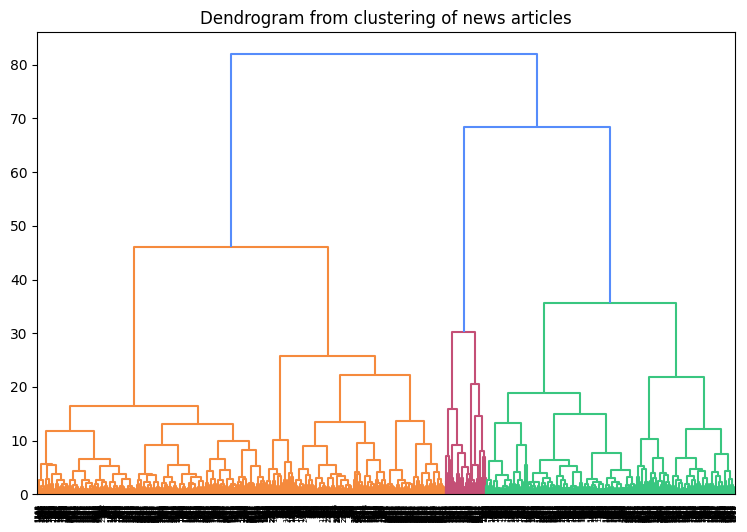

In [207]:
review_dist = 1 - review_similarity
ward_linkage = sch.linkage(review_dist, method='ward')

plt.figure(figsize=(9, 6))
sch.dendrogram(ward_linkage)
plt.title('Dendrogram from clustering of news articles')
plt.show()

Na osnovu dendrograma, deluje da bi optimalan broj klastera mogao biti izmedju 2 i 5

In [208]:
candidate_clusters = range(2,6)
silhouette_scores = []

for cl in candidate_clusters:
    cl_clusters = sch.fcluster(ward_linkage, t=cl, criterion='maxclust')
    review_dist_clipped = np.clip(review_dist, a_min=0.0, a_max=None)
    s_score = silhouette_score(review_dist_clipped, cl_clusters, random_state=RAND_STATE, metric='precomputed')
    silhouette_scores.append(s_score)

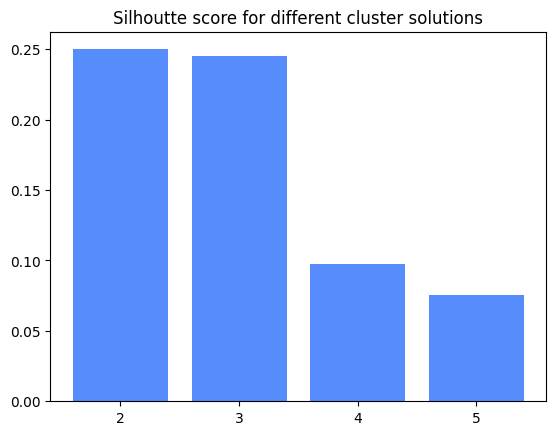

In [209]:
_, ax = plt.subplots()
ax.bar(candidate_clusters, silhouette_scores)
ax.set_title("Silhoutte score for different cluster solutions")
ax.set_xticks(candidate_clusters)
plt.show()

Na osnovu dendrograma i skora siluete za razlicite vrednosti broja klastera, biramo resenje sa 3 klastera. Iako resenje sa dva klastera ima neznatno visu vrednost za siluetu, dendrogram vise upucuje na tri klastera, a generalno se podela na dva klastera ne preferira (obicno nije mnogo zanimljiva) ako postoji priblizno dobro alternativno resenje.

In [210]:
opt_clust = sch.fcluster(ward_linkage, t=3, criterion='maxclust')
pd.Series(opt_clust).value_counts()

1    1453
3     887
2     143
Name: count, dtype: int64

### Interpretacija klastera na osnovu kljucnih reci

In [211]:
data['clust'] = opt_clust

def spacy_preprocess(txt):
    tokens = spacy_model(txt)
    tokens = [token for token in tokens if
              (not token.is_space) and
              (not token.is_punct) and
              (not token.is_stop) and
              (not token.like_num)]
    return [token.lemma_.lower() for token in tokens]

def extract_keywords_for_cluster(cluster_id, ngrams = (1,2), top_n=10):
    keywords_extractor = TfidfVectorizer(
        tokenizer=spacy_preprocess,
        token_pattern=None,
        ngram_range=ngrams,
        min_df=0.01,
        max_df=0.95)

    clust_data = data.loc[data.clust == cluster_id]
    tfidf_scores = keywords_extractor.fit_transform(clust_data['articleText_reduced'])
    candidate_keywords = keywords_extractor.get_feature_names_out()

    avg_tfidf_scores = np.asarray(tfidf_scores.mean(axis=1)).flatten()

    sorted_candidates = sorted([(keyword, score) for keyword, score in zip(candidate_keywords, avg_tfidf_scores)], key=lambda item: item[1], reverse=True)

    return sorted_candidates[:top_n]


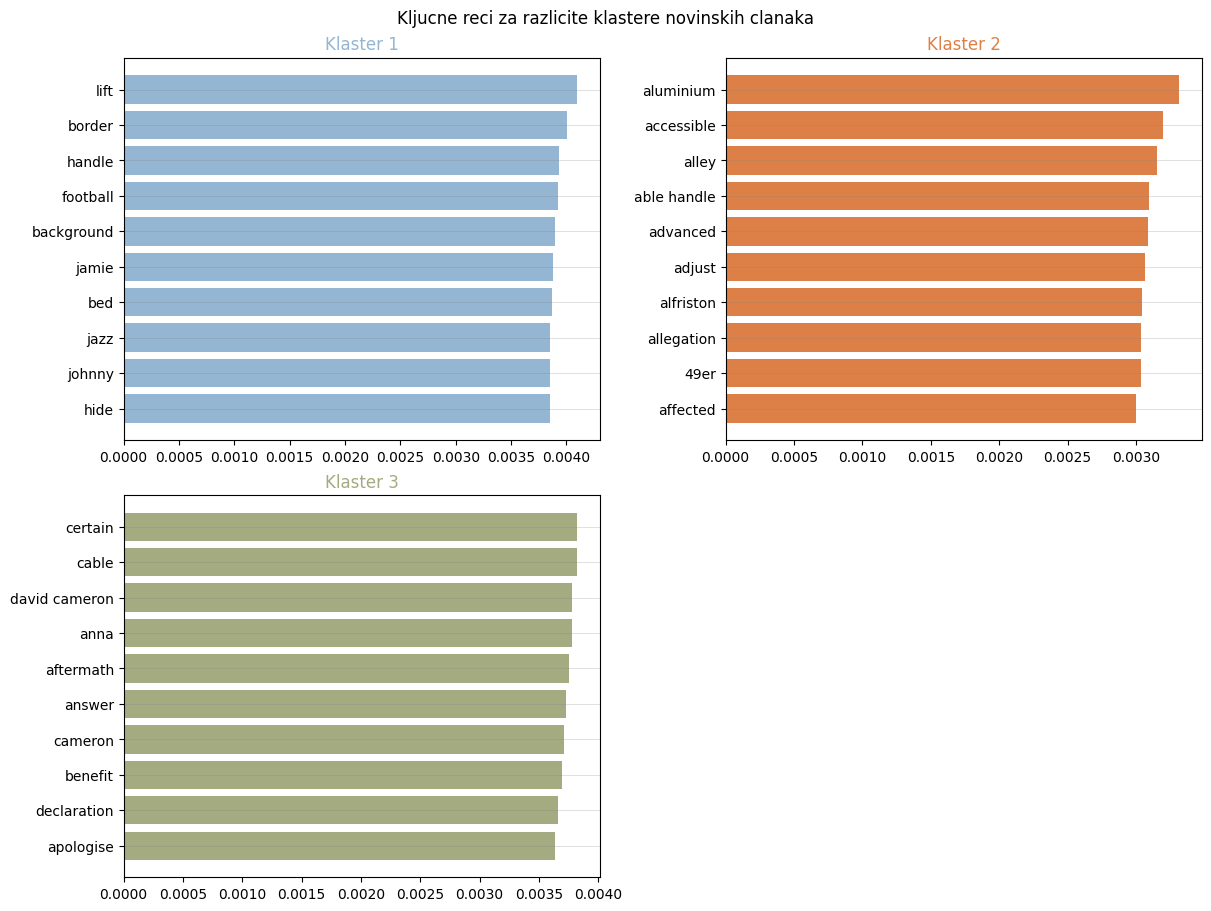

In [212]:
# NAPOMENA: primer koda za prikaz kljucnih reci po klasterima (poput koda u nastavku) bice raspoloziv na kolokvijumu

fig, axes_grid = plt.subplots(nrows=2, ncols=2, figsize=(12, 9), constrained_layout=True)
axes = axes_grid.flatten()
cmap = pypalettes.load_cmap('excel_Median')

n_clust = data['clust'].nunique()
for i in range(n_clust):

    scored_kwds = extract_keywords_for_cluster(i+1, ngrams=(1,2), top_n=10)
    scored_kwds = sorted(scored_kwds, key=lambda item: item[1])
    scores = [s for kw, s in scored_kwds]
    keywords = [kw for kw, s in scored_kwds]

    axes[i].barh(keywords, scores, color=cmap(i))
    axes[i].set_title(f"Klaster {i+1}", color=cmap(i))
    axes[i].grid(visible=True, axis='y', color='gray', alpha=0.35)

axes[n_clust].set_visible(False)

fig.suptitle("Kljucne reci za razlicite klastere novinskih clanaka")

plt.show()

S obzirom da tematski fokus klastera 2 nije jasan iz izvedenih kljucnih reci, pogledacemo desetak nasumicno izabranih naslova

In [215]:
data.loc[data.clust == 2, 'webTitle'].sample(n=10)

1738    Apple iPhone users angered by Safari browser c...
2459              10 of the UK's best railway cycle paths
2010    10 great UK canoe and paddleboarding trips wit...
1740    Chromecast with Google TV review: full smart T...
337     Tigran Hamasyan: An Ancient Observer review – ...
1658             Five breakthroughs in restoring mobility
2209    10 of the best seaside cafes and restaurants i...
1504              Which is the best tablet for an artist?
1626    What are the best keyboard shortcuts for Windows?
1876    Apple AirPods Max review: stunning sound, pain...
Name: webTitle, dtype: str

Klasteri nisu tematski jasno razdvojeni, deluje da ima dosta preklapanja, sto relativno niska vrednost za skor siluete potvrdjuje. Neki grubi opis bi mogao biti sledeci:
* klaster 1: deluje da je mix clanaka iz oblasti muzike i sporta
* klaster 2: deluje da je mix clanaka na temu tehnologije i putovanja
* klaster 3: deluje da je na temu politike